In [67]:
# import the necessary libraries
import numpy as np
import matplotlib.pyplot as plt


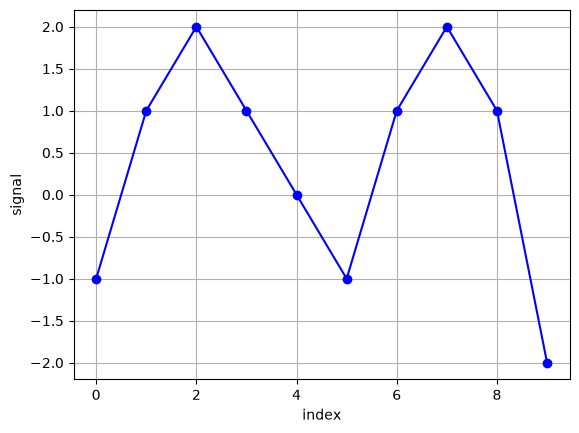

In [68]:
# Create functions to find and plot remarkable points
# plot with remarkable points

index = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])
plt.plot(index, signal, marker='o', linestyle='-', color='b')    
plt.xlabel('index')
plt.ylabel('signal')
plt.grid()



In [69]:
# create a function to find zero crossings in a sign array without zeros
def find_zero_crossings_no_zeros(signs: np.ndarray): 
    """Find positive and negative zero crossings in a sign array without zeros
    Parameters:
    ------------
    signs : np.ndarray
        An array of signs (1 for positive, -1 for negative) without zeros.
    Returns:
    ---------
    i_cross_pos : np.ndarray
        Indices of positive zero crossings (from negative to positive).
    i_cross_neg : np.ndarray
        Indices of negative zero crossings (from positive to negative).
    """
    diff = np.diff(signs) #np.diff calculates the difference between consecutive elements in the array. 
    i_cross_pos = np.where(diff > 0)[0] #indices where the difference is positive, indicating a zero crossing from negative to positive.
    i_cross_neg = np.where(diff < 0)[0] # indices where the difference is negative, indicating a zero crossing from positive to negative.
    return i_cross_pos, i_cross_neg



In [70]:
# create a function to propagate non-zero signs over zero positions in the sign array
# replace zeros with the last non-zero sign encountered in the array
def propagate_signs_over_zeros(signs: np.ndarray):
    """Manage the situation where the signal = 0 by propagating non-zero signs over zero positions in the sign array.
    parameters:
    ------------
    signs : np.ndarray
        An array of signs (1 for positive, -1 for negative) that may contain zeros
    Returns:
    ---------
    signs_no_zeros : np.ndarray
        An array of signs with zeros replaced by the last non-zero sign encountered in the array.   
        """

    signs_no_zeros = signs.copy() #create a copy of the input sign array to avoid modifying the original array.

    mask = signs_no_zeros != 0 # create a boolean mask that identifies the positions of non-zero elements in the sign array. True ≠0, False = 0
    idx = np.where(mask, np.arange(len(signs_no_zeros)), 0) # create an array of indices where non-zero elements are located. For non-zero elements, it stores their indices; for zero elements, it stores 0.   
    idx = np.maximum.accumulate(idx) # compute the cumulative maximum of the index array, effectively propagating the last non-zero index forward to fill in the positions of zeros. This ensures that each zero position will be replaced by the last non-zero sign encountered in the array.
    signs_no_zeros = signs_no_zeros[idx] # replace the zero positions in the sign array with the corresponding non-zero signs based on the propagated indices.

    if signs_no_zeros[0] == 0: # particular case of the first element being zero, we need to find the first non-zero sign and propagate it backward to fill in the initial zeros.
        i_first_nonzero = np.where(signs != 0)[0]
        if len(i_first_nonzero) > 0:
            signs_no_zeros[: i_first_nonzero[0]] = signs[i_first_nonzero[0]]

    return signs_no_zeros

In [71]:
#use the above functions (find_zero_crossings_no_zeros, propagate_signs_over_zeros) to find zero crossings in a 1D signal array
def find_zero_crossings(s: np.ndarray): # s is signal 
    """verify that the input is a 1D array and find zero crossings 
    Parameters:
    ------------
    s : np.ndarray
        A 1D array representing the signal.
    Returns:
    ---------
   i_cross_pos : np.ndarray
        Indices of positive zero crossings (from negative to positive).
    i_cross_neg : np.ndarray
        Indices of negative zero crossings (from positive to negative).
   """
#condition to check if the input signal is a 1D array. If not, it raises a ValueError.
    s = np.asarray(s)
    if s.ndim != 1: # if number of dimensions of s is different from 1
        raise ValueError("Input must be a 1D array")
# transform signal into sign (-1 for negative values, 0 for zero, 1 for positive values)
    signs = np.sign(s).astype(int)
# identitfy the index of values equal to 0
    i_zeros = np.where(signs == 0)[0]
# if there are values=0, call for the previous function to propagate non-zero signs over zero positions 
    if i_zeros.size > 0: # .size returns the number of elements in the array. If there are any zeros, it will be greater than 0.
        signs_no_zeros = propagate_signs_over_zeros(signs)
    else:
        signs_no_zeros = signs
# return the indice of zero crossing, taking care of 0 signal value
    return find_zero_crossings_no_zeros(signs_no_zeros) # call for anothor function to find zero crossings in a sign array without zeros, returns will be the return of the function find_zero_crossings_no_zeros : i_cross_pos, i_cross_neg

In [72]:
# the unit tests serve to verify the correctness of the find_zero_crossings function by checking its output against expected results for various input signals. If all assertions pass, it indicates that the function behaves as intended for the tested cases.

# verify the function with some test cases
def test_find_zero_crossings():
    """Unit tests for find_zero_crossings function.
    This function tests the find_zero_crossings function with various input signals and checks if the output matches the expected results.
    """
    s = np.array([-1, 1, -1, 1, -1])
    # expected     +  -   +  -   +
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([0, 2])) # - to + crossings at indices 0 and 2
    assert np.array_equal(i_neg, np.array([1, 3])) # + to - crossings at indices 1 and 3

    s = np.array([-1, 0, 0, 1, 0, -1])
    # expected     -     +     -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

    s = np.array([0, 0, 0, 1, 0, 0])
    # expected    no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([0, 0, 1, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([0, 1, 0, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([1, 0, 0, -1, 0, 0])
    # expected          -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([2]))

# provide additional test cases to cover more scenarios 
    s = np.array([1, 1, 1, 1, 1, 1])
    # expected         no crossing
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([0, 0, 0, 0, 0])
        # expected          no crossing
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([-1, 0, 1, 0, -1, 0, 1])
        # expected      +     -      +
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([1, 5]))
    assert np.array_equal(i_neg, np.array([3]))



# Testing the function
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.


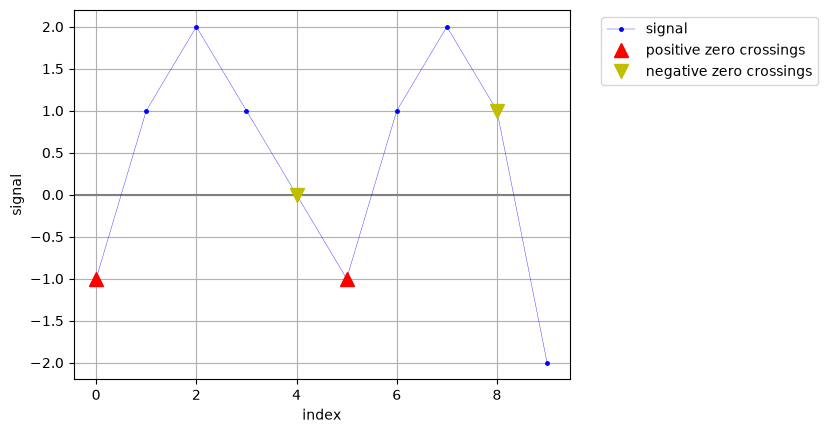

In [73]:
# plot the signal 
def plot_signal(i: np.ndarray, s: np.ndarray, color: str = "blue"):
    """Plot the signal as function of time/index with grid and zero line
    Parameters:
    ------------
    i : np.ndarray
        A 1D array representing the time or index values.
    s : np.ndarray
        A 1D array representing the signal values.
    Outputs:
    ---------  
    displays a plot
        """
    plt.axhline(y=0, color="gray", linestyle="-")  # before to be under the signal
    plt.plot(i, s, ".-", markersize=5, linewidth=0.25, color=color, label="signal")
    plt.ylabel("signal")
    plt.xlabel("index")

# mark the points 
def plot_remarkable_points(t: np.ndarray, s: np.ndarray, format: str, label: str):
    """Plot remarkable points on a signal with format and label"""
    plt.plot(t, s, format, markersize=10, label=label)

# identify the positive zero crossings 
def plot_positive_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot positive zero crossings on a signal"""
    i_pos, _ = find_zero_crossings(s)
    plot_remarkable_points(i[i_pos], s[i_pos], "^r", "positive zero crossings")

# identify the negative zero crossings
def plot_negative_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot negative zero crossings on a signal"""
    _, i_neg = find_zero_crossings(s)
    plot_remarkable_points(i[i_neg], s[i_neg], "vy", "negative zero crossings")

# combine the two previous functions to plot all zero crossings
def plot_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot all zero crossings on a signal"""
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)


def display_signal_and_crossings(i: np.ndarray, s: np.ndarray):
    """Plot signal and zero crossings with legend outside the plot and grid"""
    plt.figure()
    plot_signal(i, s)
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)
    # NOTE: legend outside does not work well with %matplotlib widget
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True)
    plt.show()


# Example usage
display_signal_and_crossings(index, signal)

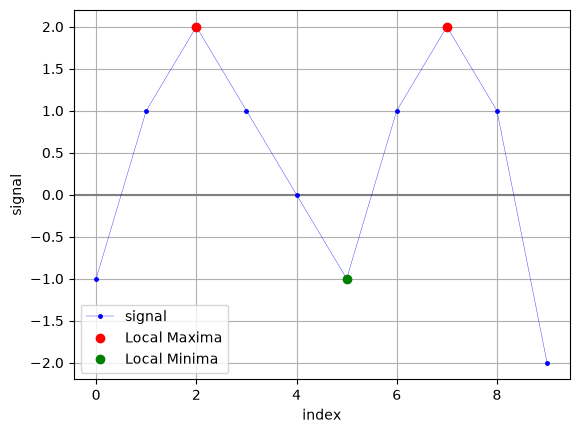

In [ ]:
# Create a function to find the local maxima and minima in a 1D signal array

# as seen in a previous course, the local maxima and minima can be found by calculating the first derivative of the signal and identifying where the derivative changes sign. A local maximum occurs when the derivative changes from positive to negative, while a local minimum occurs when the derivative changes from negative to positive.
def find_local_extrema(signal: np.ndarray):
    """Find local maxima and minima in a 1D signal array.
    Parameters:
    ------------
    signal : np.ndarray
        A 1D array representing the signal.
    Returns:
    ---------
    local_maxima : np.ndarray
        Indices of local maxima in the signal.
    local_minima : np.ndarray
        Indices of local minima in the signal.
    """
    # Calculate the first derivative of the signal
    derivative = np.diff(signal)
    
    # Identify where the derivative changes sign
    maxima_indices = np.where((derivative[:-1] > 0) & (derivative[1:] < 0))[0] + 1
    minima_indices = np.where((derivative[:-1] < 0) & (derivative[1:] > 0))[0] + 1
    
    return maxima_indices, minima_indices

# Plot the signal with local maxima and minima
def plot_signal_with_extrema(i: np.ndarray, s: np.ndarray):
    """Plot signal with local maxima and minima marked."""
    plt.figure()
    plot_signal(i, s)
    
    maxima_indices, minima_indices = find_local_extrema(s)
    
    # Plot local maxima
    plt.plot(i[maxima_indices], s[maxima_indices], 'ro', label='Local Maxima')
    
    # Plot local minima
    plt.plot(i[minima_indices], s[minima_indices], 'go', label='Local Minima')
    
    plt.legend()
    plt.grid(True)
    plt.show()

plot_signal_with_extrema(index, signal)